In [3]:
import pandas as pd
import matplotlib.pyplot as plt

In [4]:
df = pd.read_csv(
    "/content/WA_Fn-UseC_-Telco-Customer-Churn.csv"
)

df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

df.info()

Dataset shape: (7043, 21)

Column names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   Online

In [6]:
print("Missing values:")
print(df.isnull().sum())

print("Duplicate rows:", df.duplicated().sum())

print("Churn categories:")
print(df["Churn"].value_counts())

Missing values:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64
Duplicate rows: 0
Churn categories:
Churn
No     5174
Yes    1869
Name: count, dtype: int64


In [7]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

print(df["TotalCharges"].isnull().sum())

df[df["TotalCharges"].isnull()][
    ["tenure", "MonthlyCharges", "TotalCharges"]
]

df = df.dropna(subset=["TotalCharges"]).copy()

print("Rows after cleaning:", len(df))

11
Rows after cleaning: 7032


In [8]:
churn_rate = (df["Churn"] == "Yes").mean() * 100

print(f"Customer churn rate: {churn_rate:.2f}%")

Customer churn rate: 26.58%


In [9]:
contract_churn = df.groupby("Contract")["Churn"].apply(
    lambda x: (x == "Yes").mean() * 100
)

print(contract_churn)

Contract
Month-to-month    42.709677
One year          11.277174
Two year           2.848665
Name: Churn, dtype: float64


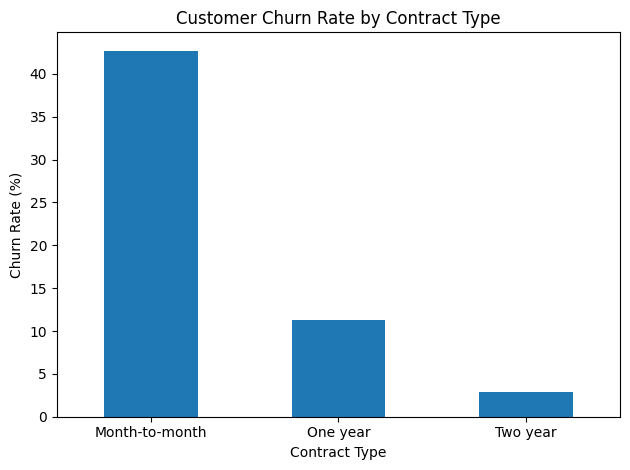

In [10]:
contract_churn.plot(kind="bar")

plt.title("Customer Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Identify the contract group with the highest churn and discuss one possible business action

Be careful: an association doesn't prove that the contract type itself causes customers to leave.

In [11]:
import sqlite3

conn = sqlite3.connect(":memory:")

df.to_sql("customers", conn, index=False, if_exists="replace")

7032

In [12]:
query = """
SELECT Contract, COUNT(*) AS total_customers
FROM customers
GROUP BY Contract
ORDER BY total_customers DESC;
"""

pd.read_sql_query(query, conn)

,Contract,total_customers
0,Month-to-month,3875
1,Two year,1685
2,One year,1472


In [13]:
query = """
SELECT
    Contract,
    COUNT(*) AS total_customers,
    SUM(CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END)
        AS churned_customers,
    ROUND(
        100.0 * SUM(CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END)
        / COUNT(*), 2
    ) AS churn_rate_percent
FROM customers
GROUP BY Contract
ORDER BY churn_rate_percent DESC;
"""

pd.read_sql_query(query, conn)

,Contract,total_customers,churned_customers,churn_rate_percent
0,Month-to-month,3875,1655,42.71
1,One year,1472,166,11.28
2,Two year,1685,48,2.85


In [16]:
query = """
SELECT
    InternetService,
    COUNT(*) AS total_customers,
    ROUND(
        100.0 * SUM(
            CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END
        ) / COUNT(*), 2
    ) AS churn_rate_percent
FROM customers
GROUP BY InternetService
ORDER BY churn_rate_percent DESC;
"""

result = pd.read_sql_query(query, conn)
print(result)

  InternetService  total_customers  churn_rate_percent
0     Fiber optic             3096               41.89
1             DSL             2416               19.00
2              No             1520                7.43


In [17]:
X = df.drop(columns=["Churn", "customerID"])
y = (df["Churn"] == "Yes").astype(int)

print("Input features:", X.shape[1])
print("Target values:")
print(y.value_counts())

Input features: 19
Target values:
Churn
0    5163
1    1869
Name: count, dtype: int64


In [18]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 5625
Testing records: 1407


In [19]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    confusion_matrix,
    classification_report
)

numeric_cols = X.select_dtypes(include="number").columns
categorical_cols = X.select_dtypes(
    include=["object", "category"]
).columns

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_cols),
    ("categorical", categorical_pipeline, categorical_cols)
])

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  Index(['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges'], dtype='object')),
                                                 ('categorical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  Index(['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines',
       'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
       'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract',
       'PaperlessBilling', 'PaymentMethod'],
      dtype='object'))])),
                ('classifier', LogisticRegression(max_iter=1000))])

In [20]:
predictions = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, predictions))
print("Precision:", precision_score(y_test, predictions))
print("Recall:", recall_score(y_test, predictions))

print("\nConfusion matrix:")
print(confusion_matrix(y_test, predictions))

print("\nClassification report:")
print(classification_report(y_test, predictions))

Accuracy: 0.8038379530916845
Precision: 0.6484848484848484
Recall: 0.5721925133689839

Confusion matrix:
[[917 116]
 [160 214]]

Classification report:
              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1033
           1       0.65      0.57      0.61       374

    accuracy                           0.80      1407
   macro avg       0.75      0.73      0.74      1407
weighted avg       0.80      0.80      0.80      1407



In [21]:
# 1. Overall churn rate
overall_churn = (df["Churn"] == "Yes").mean() * 100

# 2. Churn rate by contract
contract_churn = (
    df.groupby("Contract")["Churn"]
      .apply(lambda x: (x == "Yes").mean() * 100)
      .sort_values(ascending=False)
)

# 3. Churn rate by internet service
internet_churn = (
    df.groupby("InternetService")["Churn"]
      .apply(lambda x: (x == "Yes").mean() * 100)
      .sort_values(ascending=False)
)

# 4. Average tenure for churned vs retained customers
tenure_comparison = df.groupby("Churn")["tenure"].mean()

print(f"Overall churn rate: {overall_churn:.2f}%")
print("\nChurn rate by contract:")
print(contract_churn.round(2))

print("\nChurn rate by internet service:")
print(internet_churn.round(2))

print("\nAverage tenure by churn status:")
print(tenure_comparison.round(2))

Overall churn rate: 26.58%

Churn rate by contract:
Contract
Month-to-month    42.71
One year          11.28
Two year           2.85
Name: Churn, dtype: float64

Churn rate by internet service:
InternetService
Fiber optic    41.89
DSL            19.00
No              7.43
Name: Churn, dtype: float64

Average tenure by churn status:
Churn
No     37.65
Yes    17.98
Name: tenure, dtype: float64


In [22]:
from sklearn.metrics import accuracy_score, precision_score, recall_score

predictions = model.predict(X_test)

print(f"Accuracy:  {accuracy_score(y_test, predictions):.4f}")
print(f"Precision: {precision_score(y_test, predictions):.4f}")
print(f"Recall:    {recall_score(y_test, predictions):.4f}")

Accuracy:  0.8038
Precision: 0.6485
Recall:    0.5722


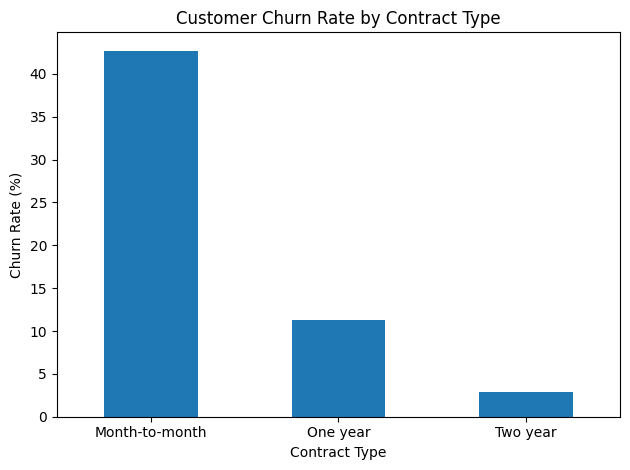

In [23]:
import matplotlib.pyplot as plt

contract_churn = (
    df.groupby("Contract")["Churn"]
      .apply(lambda x: (x == "Yes").mean() * 100)
)

ax = contract_churn.plot(kind="bar")
ax.set_title("Customer Churn Rate by Contract Type")
ax.set_xlabel("Contract Type")
ax.set_ylabel("Churn Rate (%)")
ax.tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.savefig("churn_by_contract.png", dpi=150, bbox_inches="tight")
plt.show()

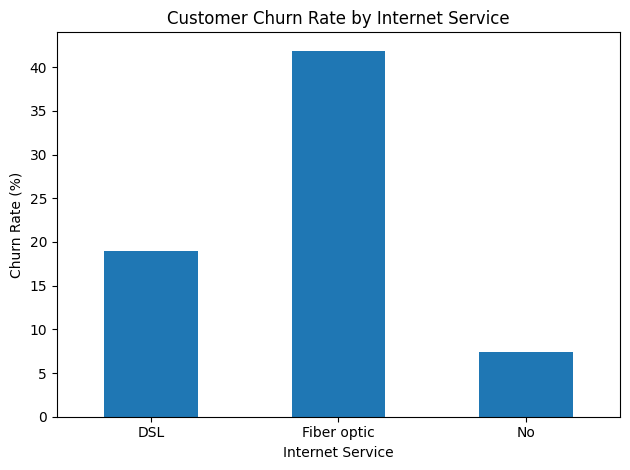

In [24]:
internet_churn = (
    df.groupby("InternetService")["Churn"]
      .apply(lambda x: (x == "Yes").mean() * 100)
)

ax = internet_churn.plot(kind="bar")
ax.set_title("Customer Churn Rate by Internet Service")
ax.set_xlabel("Internet Service")
ax.set_ylabel("Churn Rate (%)")
ax.tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.savefig("churn_by_internet_service.png", dpi=150, bbox_inches="tight")
plt.show()

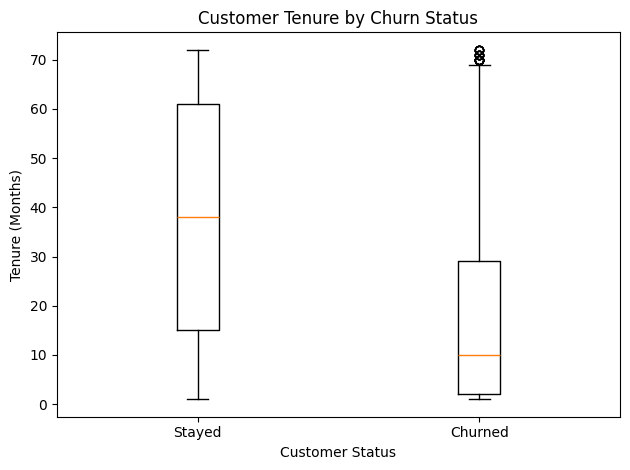

In [25]:
tenure_data = [
    df.loc[df["Churn"] == "No", "tenure"],
    df.loc[df["Churn"] == "Yes", "tenure"]
]

plt.figure()
plt.boxplot(tenure_data, tick_labels=["Stayed", "Churned"])
plt.title("Customer Tenure by Churn Status")
plt.xlabel("Customer Status")
plt.ylabel("Tenure (Months)")
plt.tight_layout()
plt.savefig("churn_by_tenure.png", dpi=150, bbox_inches="tight")
plt.show()

In [26]:
import sqlite3

conn = sqlite3.connect(":memory:")
df.to_sql("customers", conn, index=False, if_exists="replace")

7032

In [27]:
query = """
SELECT Contract, COUNT(*) AS total_customers
FROM customers
GROUP BY Contract;
"""

pd.read_sql_query(query, conn)

,Contract,total_customers
0,Month-to-month,3875
1,One year,1472
2,Two year,1685


In [28]:
from sklearn.metrics import confusion_matrix

print(confusion_matrix(y_test, predictions))

[[917 116]
 [160 214]]
